<a href="https://colab.research.google.com/github/Katrises/lab.statistic/blob/main/Lab01_Sprint1_Wine_Quality.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a id="start"></a>
# Lab01 - sprint 1

Работу выполняли:
Панова Екатерина 502874
Сергеева Василиса 502556
Самоховец Анна 504789

**Инфохимия. Спирт, плотность и остаточный сахар в красном вине**

Цель работы — описать три случайные величины, проверить их зависимость и посмотреть,
насколько хорошо случайная выборка воспроизводит исходные данные.
Используется красное вино из Wine Quality. Белое вино в расчёты не включается:
смешивание двух типов затруднило бы объяснение распределений.

Это только первый спринт. Генератор случайных чисел относится ко второму спринту.

**Порядок работы:**

1. [Данные, очистка и определения](#data).
2. [Содержание спирта](#rv1), [плотность](#rv2), [остаточный сахар](#rv3).
3. [Нормализация](#normalization).
4. [Вероятности, зависимость и три гипотезы](#dependence).
5. [Выборки с возвращением и без возвращения](#sampling).
6. [Эмпирическая проверка состоятельности](#consistency).
7. [Опыт с искусственными выбросами](#outliers).
8. [Выводы, критерии и литература](#resume).

**Как запустить.** Распаковать архив, открыть этот ноутбук и выполнить ячейки сверху вниз.
CSV лежит в папке `data`. Если открыт только ноутбук, данные загрузятся с UCI при наличии
интернета. Нужны `pandas`, `numpy`, `matplotlib`, `scipy` и `IPython`.
Графики и результаты последнего выполнения уже сохранены в файле.


<a id="data"></a>
## 0. Данные и обозначения

Источник: [UCI Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality),
[DOI датасета](https://doi.org/10.24432/C56S3T).
В приложенном архиве находятся `winequality-red.csv`, `winequality-white.csv` и описание
`winequality.names`. Одна строка красного набора — результаты анализа одного образца вина.
Описание происхождения и единицы измерения приведены в статье авторов, таблица 1 [2].

| Обозначение | Столбец | Величина | Единица |
|---|---|---|---|
| $A$ | `alcohol` | Объёмная доля спирта | % об. |
| $D$ | `density` | Плотность | г/см³ |
| $S$ | `residual sugar` | Остаточный сахар | г/л |

Для учебных опытов **генеральной совокупностью считаются все строки красного CSV**.
Это конечная совокупность, которую можно полностью проверить.
Вино вообще или всё производство Vinho Verde этой таблицей не исчерпывается.
О случайном отборе исходных образцов, производителях и партиях подробной информации нет,
поэтому перенос результатов на всё вино ограничен.

### Загрузка и проверка качества


In [33]:
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown

SEED = 42
pd.set_option("display.max_columns", 15)
pd.set_option("display.max_rows", 25)
pd.set_option("display.float_format", lambda x: f"{x:.6g}")

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.2,
})

local_files = [Path("data/winequality-red.csv"), Path("winequality-red.csv")]
source = next((path for path in local_files if path.exists()), None)
if source is None:
    source = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"

wine_raw = pd.read_csv(source, sep=";")
columns = ["alcohol", "density", "residual sugar"]
names = {"alcohol": "Спирт", "density": "Плотность", "residual sugar": "Остаточный сахар"}
units = {"alcohol": "% об.", "density": "г/см³", "residual sugar": "г/л"}
colors = {"alcohol": "#75445b", "density": "#327c83", "residual sugar": "#b47832"}

display(wine_raw.head())
print("Размер исходного набора:", wine_raw.shape)
display(pd.DataFrame({"тип": wine_raw.dtypes.astype(str), "пропуски": wine_raw.isna().sum()}))

wine = wine_raw.dropna(subset=columns).copy()
N = len(wine)
print("До удаления пропусков:", len(wine_raw), "после:", N)
print("Бесконечных значений:", np.isinf(wine[columns].to_numpy()).sum())
print("Полностью повторяющихся строк:", wine.duplicated().sum())
print("Неположительных значений:", (wine[columns] <= 0).sum().to_dict())


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.7,0,1.9,0.076,11,34,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0,2.6,0.098,25,67,0.9968,3.2,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15,54,0.997,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17,60,0.998,3.16,0.58,9.8,6
4,7.4,0.7,0,1.9,0.076,11,34,0.9978,3.51,0.56,9.4,5


Размер исходного набора: (1599, 12)


,тип,пропуски
fixed acidity,float64,0
volatile acidity,float64,0
citric acid,float64,0
residual sugar,float64,0
chlorides,float64,0
free sulfur dioxide,float64,0
total sulfur dioxide,float64,0
density,float64,0
pH,float64,0
sulphates,float64,0


До удаления пропусков: 1599 после: 1599
Бесконечных значений: 0
Полностью повторяющихся строк: 240
Неположительных значений: {'alcohol': 0, 'density': 0, 'residual sugar': 0}


Пропусков и бесконечных значений нет. Осталось **1599 строк**.
Есть **240 полных повторов**, то есть 1359 различных строк по всем 12 столбцам.
Их нельзя уверенно назвать ошибкой: без идентификаторов неизвестно, это повторная запись
или разные образцы с одинаковыми округлёнными характеристиками.

Основное описание и опыты с выборками используют все 1599 строк.
Для трёх формальных проверок зависимости ниже берётся отдельная копия без полных повторов,
чтобы одинаковые записи не увеличивали число наблюдений в тесте.
Это меняет веса наблюдений, поэтому рядом сравниваются описательные результаты двух вариантов.
Удаление повторов само по себе не гарантирует независимость образцов.

### Что здесь является случайным

Зададим опыт: выбирается случайный номер строки $I$ из $1,\ldots,N$, причём
$P(I=i)=1/N$. Тогда $A=a_I$, $D=d_I$, $S=s_I$ — функции случайного исхода,
то есть случайные величины. Они невырождены: в таблице у каждой есть несколько значений.
До выбора номера конкретный результат неизвестен.

Для нового реального образца остаются различия состава, условий производства и погрешности
измерений. Здесь не утверждается, что химические процессы «не подчиняются формулам».
Формула может связывать свойства при известных исходных условиях, но точное значение
для случайно выбранного образца нельзя получить из имеющейся информации до выбора и измерения.
Одного ненулевого разброса для доказательства случайной природы было бы недостаточно.

Физические величины непрерывны, но файл содержит конечный набор измеренных чисел.
Его эмпирическое распределение дискретно. Поэтому вероятность записанного значения
может быть положительной; у идеальной непрерывной модели вероятность одной точки равна нулю.

### Метрики и эмпирическое распределение

Для различных записанных значений $x_j$ подсчитываются частоты $n_j$:

$$p_j=\frac{n_j}{N},\qquad \sum_jp_j=1,\qquad
F_N(t)=\frac{1}{N}\sum_{i=1}^{N}\mathbf{1}(x_i\leq t).$$

Для случайной строки таблицы математическое ожидание и дисперсия известны точно:

$$E_N(X)=\sum_jx_jp_j=\bar x_N,\qquad
V_N=\sum_j(x_j-\bar x_N)^2p_j=\frac{1}{N}\sum_i(x_i-\bar x_N)^2.$$

Отдельно выводится исправленная дисперсия $s^2=\sum_i(x_i-\bar x)^2/(n-1)$
и её квадратный корень $s$. В `pandas` для них используется `ddof=1`.
При описании конечной генеральной совокупности $V_N$ используется `ddof=0`.

Медиана совпадает с **50-м процентилем**, то есть квантилем уровня 0.5 (вторым квартилем).
Сумма значений включена как в ДЗ, хотя сумма плотностей или процентов не характеризует
физическую смесь. Мода зависит от точности записи измерений.

В отличие от расчёта среднего по столбцу уникальных значений, здесь все метрики учитывают
повторяемость наблюдений. Иначе редкое значение и часто встречающееся получили бы одинаковый вес.


In [34]:
def frequency_table(series):
    table = series.value_counts().sort_index().rename_axis("x").reset_index(name="count")
    table["p_i"] = table["count"] / series.count()
    table["F_N(x)"] = table["p_i"].cumsum()
    return table


def describe_values(series):
    s = pd.Series(series).dropna()
    q1, q2, q3 = s.quantile([0.25, 0.5, 0.75])
    return pd.Series({
        "Количество": s.count(),
        "Уникальных значений": s.nunique(),
        "Сумма": s.sum(),
        "Среднее": s.mean(),
        "Медиана": s.median(),
        "Мода (все значения)": ", ".join(f"{x:g}" for x in s.mode()),
        "Минимум": s.min(),
        "Максимум": s.max(),
        "Размах": s.max() - s.min(),
        "Дисперсия, ddof=0": s.var(ddof=0),
        "Дисперсия, ddof=1": s.var(ddof=1),
        "Стандартное отклонение, ddof=1": s.std(ddof=1),
        "Q1 (25%)": q1,
        "Q2 (50%)": q2,
        "Q3 (75%)": q3,
        "IQR": q3 - q1,
        "Асимметрия": s.skew(),
        "Эксцесс": s.kurt(),
    })


def show_eda(column):
    s = wine[column]
    table = frequency_table(s)
    display(describe_values(s).to_frame("Значение"))
    print("Таблица частот: первые и последние значения")
    display(pd.concat([table.head(8), table.tail(3)]))

    probability_sum = 0.0
    expectation = 0.0
    for row in table.itertuples(index=False, name=None):
        x, count, p_i, cumulative = row
        probability_sum += p_i
        expectation += x * p_i
    print(f"Сумма p_i через sum(): {table['p_i'].sum():.17g}")
    print(f"Сумма p_i через цикл: {probability_sum:.17g}")
    print(f"E_N(X) = sum(x_j * p_j): {expectation:.9g}")
    print(f"Среднее по всем строкам: {s.mean():.9g}")
    assert np.isclose(table["p_i"].sum(), 1)
    assert np.isclose(expectation, s.mean())

    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    print(f"Границы правила 1.5 IQR: {low:.7g}; {high:.7g}")
    print("Число наблюдений за границами:", ((s < low) | (s > high)).sum())

    fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
    axes[0].hist(s, bins=15, color=colors[column], edgecolor="white")
    axes[0].set(title="Гистограмма: 15 интервалов", xlabel=units[column], ylabel="Число наблюдений")
    pad = (s.max() - s.min()) * 0.03
    x_plot = np.r_[s.min() - pad, table["x"], s.max() + pad]
    y_plot = np.r_[0, table["F_N(x)"], 1]
    axes[1].step(x_plot, y_plot, where="post", color=colors[column])
    axes[1].set(xlabel=units[column], ylabel="F_N(x) = P(X ≤ x)", ylim=(-0.02, 1.03), title="Эмпирическая функция распределения")
    axes[2].boxplot(s, showmeans=True)
    axes[2].set_xticks([1], [names[column]])
    axes[2].set(ylabel=units[column], title="Ящик с усами")
    if column == "density":
        axes[0].ticklabel_format(axis="x", style="plain", useOffset=False)
        axes[1].ticklabel_format(axis="x", style="plain", useOffset=False)
        axes[2].ticklabel_format(axis="y", style="plain", useOffset=False)
    fig.suptitle(names[column])
    plt.tight_layout()
    plt.show()
    return table


frequencies = {}


В гистограммах выбрано 15 интервалов: их достаточно, чтобы увидеть центр и хвосты при
1599 строках. Это способ отображения, а не подбор параметра распределения.
Все наблюдения, включая крайние, остаются на графиках.

Ступени функции распределения связаны с конечным объёмом и округлением измерений.
Крошечное отличие суммы вероятностей от 1 в последних знаках возникает из-за представления
чисел с плавающей точкой и порядка сложения. В математике сумма равна ровно 1.
Проверяется близость с численным допуском, а не буквальное равенство двоичных чисел.


<a id="rv1"></a>
## Random Variable 01 — содержание спирта

### Description

$A$ — объёмная доля спирта у случайно выбранного образца. Результат связан с исходной
сахаристостью, ходом брожения и обработкой вина. Эти условия различаются и полностью
не записаны в таблице. По номеру будущего случайного образца или только по остатку сахара
точную долю спирта заранее не получить.

### EDA & Distribution


,Значение
Количество,1599
Уникальных значений,65
Сумма,16666.3
Среднее,10.423
Медиана,10.2
Мода (все значения),9.5
Минимум,8.4
Максимум,14.9
Размах,6.5
"Дисперсия, ddof=0",1.13494


Таблица частот: первые и последние значения


,x,count,p_i,F_N(x)
0,8.4,2,0.00125078,0.00125078
1,8.5,1,0.000625391,0.00187617
2,8.7,2,0.00125078,0.00312695
3,8.8,2,0.00125078,0.00437774
4,9,30,0.0187617,0.0231395
5,9.05,1,0.000625391,0.0237649
6,9.1,23,0.014384,0.0381488
7,9.2,72,0.0450281,0.083177
62,13.6,4,0.00250156,0.994997
63,14,7,0.00437774,0.999375


Сумма p_i через sum(): 1
Сумма p_i через цикл: 1.0000000000000009
E_N(X) = sum(x_j * p_j): 10.4229831
Среднее по всем строкам: 10.4229831
Границы правила 1.5 IQR: 7.1; 13.5
Число наблюдений за границами: 13


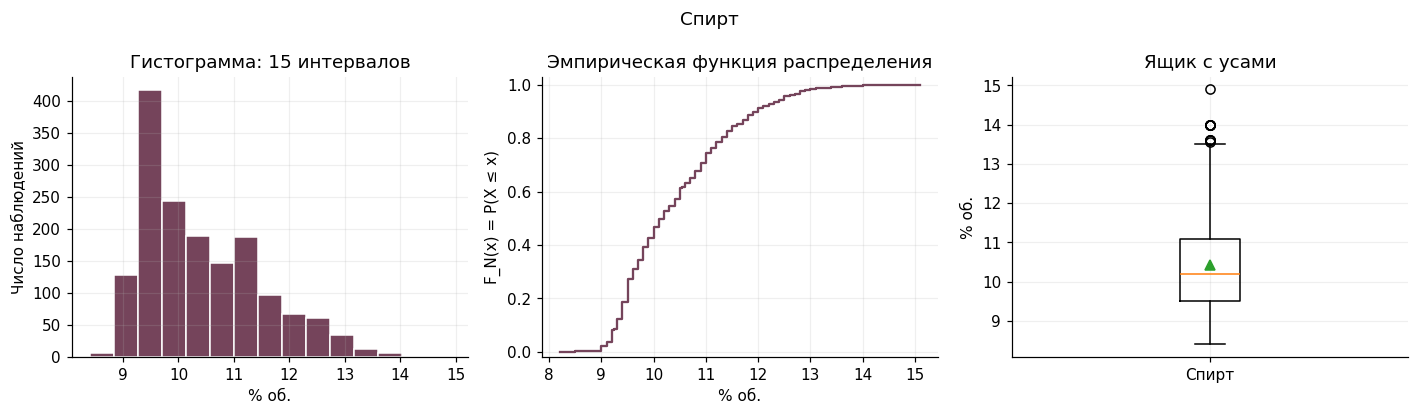

In [35]:
frequencies["alcohol"] = show_eda("alcohol")


Среднее содержание спирта — **10.423 % об.**, медиана — **10.2 % об.**, мода — **9.5 % об.**
Среднее выше медианы, и асимметрия положительна: сравнительно крепкие образцы вытягивают
правый хвост. Весь диапазон — от 8.4 до 14.9 % об.

Точным описанием случайного выбора строки остаётся эмпирическое распределение.
В качестве простой гладкой модели далее рассматривается логнормальное распределение.
Оно положительно и допускает правую асимметрию, но эти свойства ещё не доказывают соответствие данным.

### Independence & Estimations

Среднее и дисперсия приведены выше. Их устойчивость при увеличении выборки проверяется
в опыте с повторными выборками, а зависимость спирта от двух других величин —
в совместном анализе. Сравнение проводится по тем же строкам образцов.


<a id="rv2"></a>
## Random Variable 02 — плотность

### Description

$D$ — плотность случайного образца. Формула $\rho=m/V$ — определение плотности, но массы
и объёма будущего образца у нас нет. На плотность влияют спирт, сахар и другие растворённые
вещества, а также условия измерения. Двух выбранных столбцов недостаточно для точного расчёта.

### EDA & Distribution


,Значение
Количество,1599
Уникальных значений,436
Сумма,1593.8
Среднее,0.996747
Медиана,0.99675
Мода (все значения),0.9972
Минимум,0.99007
Максимум,1.00369
Размах,0.01362
"Дисперсия, ddof=0",3.5598e-06


Таблица частот: первые и последние значения


,x,count,p_i,F_N(x)
0,0.99007,2,0.00125078,0.00125078
1,0.9902,1,0.000625391,0.00187617
2,0.99064,2,0.00125078,0.00312695
3,0.9908,1,0.000625391,0.00375235
4,0.99084,1,0.000625391,0.00437774
5,0.9912,1,0.000625391,0.00500313
6,0.9915,1,0.000625391,0.00562852
7,0.99154,1,0.000625391,0.00625391
433,1.00315,3,0.00187617,0.998124
434,1.0032,1,0.000625391,0.998749


Сумма p_i через sum(): 0.99999999999999989
Сумма p_i через цикл: 1.000000000000004
E_N(X) = sum(x_j * p_j): 0.996746679
Среднее по всем строкам: 0.996746679
Границы правила 1.5 IQR: 0.9922475; 1.001187
Число наблюдений за границами: 45


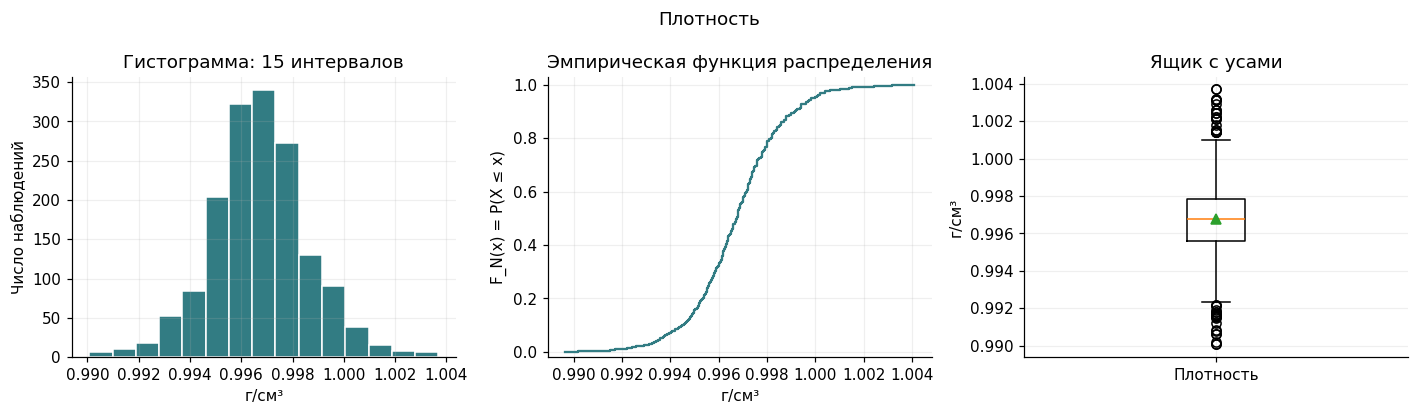

In [36]:
frequencies["density"] = show_eda("density")


Среднее **0.996747 г/см³** почти совпадает с медианой **0.996750 г/см³**.
Асимметрия близка к нулю. Плотность заметно ближе к симметричному распределению, чем спирт
и сахар. Стандартное отклонение равно примерно **0.001887 г/см³**.

Для гладкого приближения используется нормальное распределение. Его пригодность здесь
оценивается по графику и квантилям; строгая нормальность не объявляется доказанной.
При вычислении вероятностей ниже всё равно используются наблюдаемые частоты.

### Independence & Estimations

Плотность физически связана с составом, поэтому её независимость от спирта и сахара нельзя
предположить заранее. Эти связи проверяются в разделе с гипотезами.
Точность оценок рассматривается вместе с другими величинами в разделе о состоятельности.


<a id="rv3"></a>
## Random Variable 03 — остаточный сахар

### Description

$S$ — концентрация сахара, оставшегося после брожения, у случайного образца.
Даже при одной доле спирта остаток сахара может различаться: неизвестны исходная
концентрация, степень завершения брожения и особенности обработки.
Поэтому простого точного пересчёта $A$ в $S$ для всех строк нет.

### EDA & Distribution


,Значение
Количество,1599
Уникальных значений,91
Сумма,4059.55
Среднее,2.53881
Медиана,2.2
Мода (все значения),2
Минимум,0.9
Максимум,15.5
Размах,14.6
"Дисперсия, ddof=0",1.98665


Таблица частот: первые и последние значения


,x,count,p_i,F_N(x)
0,0.9,2,0.00125078,0.00125078
1,1.2,8,0.00500313,0.00625391
2,1.3,5,0.00312695,0.00938086
3,1.4,35,0.0218887,0.0312695
4,1.5,30,0.0187617,0.0500313
5,1.6,58,0.0362727,0.0863039
6,1.65,2,0.00125078,0.0875547
7,1.7,76,0.0475297,0.135084
88,13.9,1,0.000625391,0.998124
89,15.4,2,0.00125078,0.999375


Сумма p_i через sum(): 1
Сумма p_i через цикл: 1.000000000000002
E_N(X) = sum(x_j * p_j): 2.5388055
Среднее по всем строкам: 2.5388055
Границы правила 1.5 IQR: 0.85; 3.65
Число наблюдений за границами: 155


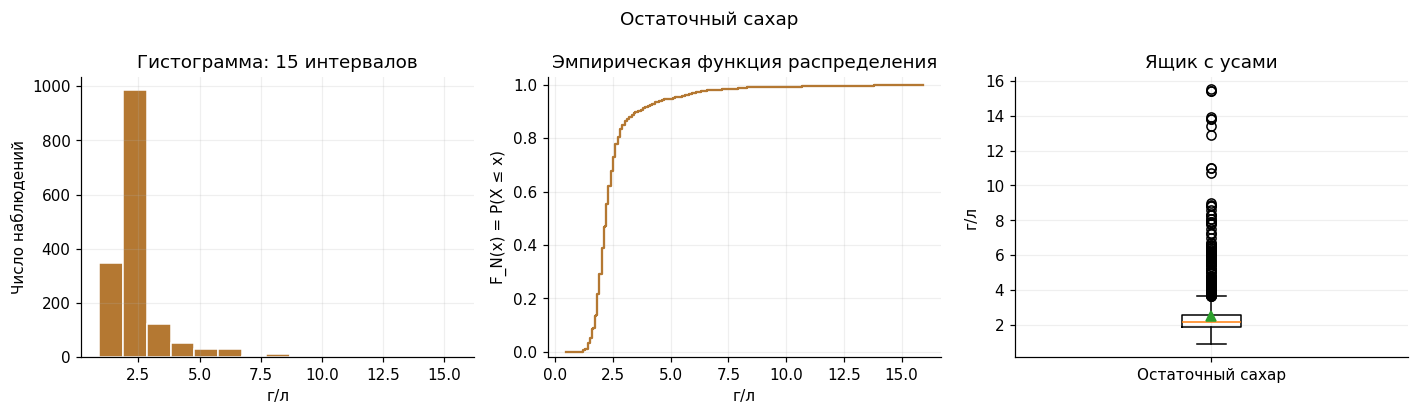

In [37]:
frequencies["residual sugar"] = show_eda("residual sugar")


У сахара среднее **2.539 г/л**, медиана **2.2 г/л**, мода **2.0 г/л**.
Верхняя граница достигает **15.5 г/л**. Асимметрия около **4.54**, поэтому среднее заметно
зависит от редких больших значений. Для описания типичного образца полезно указывать
медиану и межквартильный интервал вместе со средним.

Логнормальная модель соответствует положительной области и правому хвосту, но её форму
нужно сравнить с реальными данными. Значения за границами 1.5 IQR не удаляются автоматически:
сам по себе статистический флаг не означает ошибку измерения.

### Independence & Estimations

Зависимость сахара от плотности и спирта проверяется ниже.
Из-за длинного хвоста оценка дисперсии сахара может меняться сильнее,
чем оценка среднего; это проверяется повторными выборками.


<a id="models"></a>
## 1. Математические модели распределений

Эмпирический закон уже определён через $p_j$ и $F_N$. Он точно описывает конечную таблицу,
но за её пределами остаётся оценкой неизвестного распределения.

### Нормальная модель для плотности

Если $X\sim N(\mu,\sigma^2)$, то [3]

$$f(x)=\frac{1}{\sigma\sqrt{2\pi}}
\exp\left(-\frac{(x-\mu)^2}{2\sigma^2}\right),\quad x\in\mathbb R,\quad\sigma>0.$$

$$F(x)=\Phi\left(\frac{x-\mu}{\sigma}\right),\qquad E(X)=\mu,\qquad
\operatorname{Var}(X)=\sigma^2.$$

Кривая симметрична, среднее и медиана совпадают. Для подгонки берутся
$\hat\mu=\bar x$ и $\hat\sigma^2=N^{-1}\sum_i(x_i-\bar x)^2$ — оценки максимального правдоподобия.
Отрицательные значения математически разрешены, поэтому для физической плотности
это приближение; при оценённых параметрах масса в отрицательной области пренебрежимо мала.

### Логнормальная модель для спирта и сахара

Пусть $Y=\ln(X/x_0)\sim N(\mu_{\log},\sigma_{\log}^2)$, где $x_0$ — одна единица
измерения соответствующего столбца. Тогда [4]

$$f(x)=\frac{1}{x\sigma_{\log}\sqrt{2\pi}}
\exp\left(-\frac{(\ln(x/x_0)-\mu_{\log})^2}{2\sigma_{\log}^2}\right),\quad x>0.$$

$$F(x)=\Phi\left(\frac{\ln(x/x_0)-\mu_{\log}}{\sigma_{\log}}\right),\qquad
E(X)=x_0 e^{\mu_{\log}+\sigma_{\log}^2/2}.$$

$$\operatorname{Var}(X)=x_0^2(e^{\sigma_{\log}^2}-1)e^{2\mu_{\log}+\sigma_{\log}^2},
\qquad \operatorname{Med}(X)=x_0 e^{\mu_{\log}}.$$

В коде используются численные значения в выбранных единицах, поэтому $x_0=1$.
Параметры оцениваются как среднее и стандартное отклонение логарифмов (`ddof=0`).
Это выбор удобной формы, а не доказательство мультипликативного механизма брожения.
Модель имеет неограниченный правый хвост; для доли спирта это физически лишь локальное приближение.

### Сопоставление с данными

Сравним плотности и квантили 5%, 25%, 50%, 75%, 95%. На графике Q–Q хорошему приближению
соответствуют точки вдоль диагонали. Тесты нормальности и другие дополнительные гипотезы
здесь не проводятся, чтобы всего в работе осталось три формальные гипотезы.


Спирт — Логнормальное — единицы: % об.


,Уровень,Данные,Модель,Модель − данные
0,0.05,9.2,8.81448,-0.385515
1,0.25,9.5,9.70203,0.202027
2,0.5,10.2,10.3711,0.171074
3,0.75,11.1,11.0863,-0.0137411
4,0.95,12.5,12.2025,-0.297451


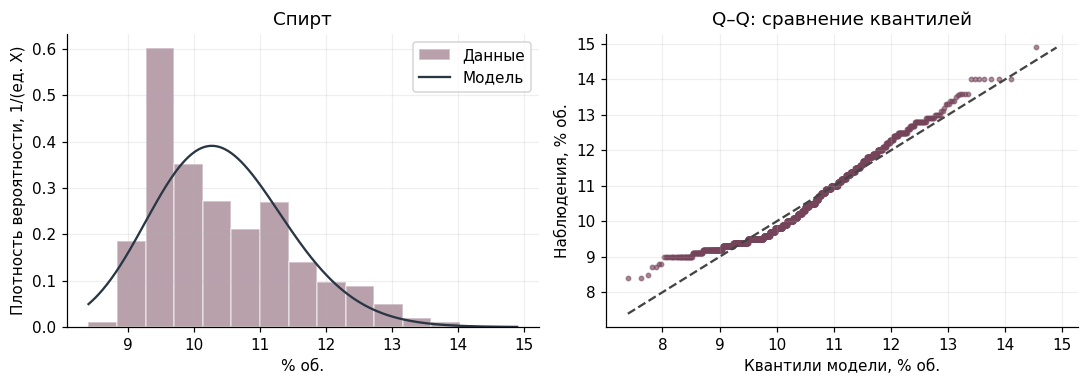

Плотность — Нормальное — единицы: г/см³


,Уровень,Данные,Модель,Модель − данные
0,0.05,0.993598,0.993643,4.5262e-05
1,0.25,0.9956,0.995474,-0.00012591
2,0.5,0.99675,0.996747,-3.32083e-06
3,0.75,0.997835,0.998019,0.000184268
4,0.95,1,0.99985,-0.000149904


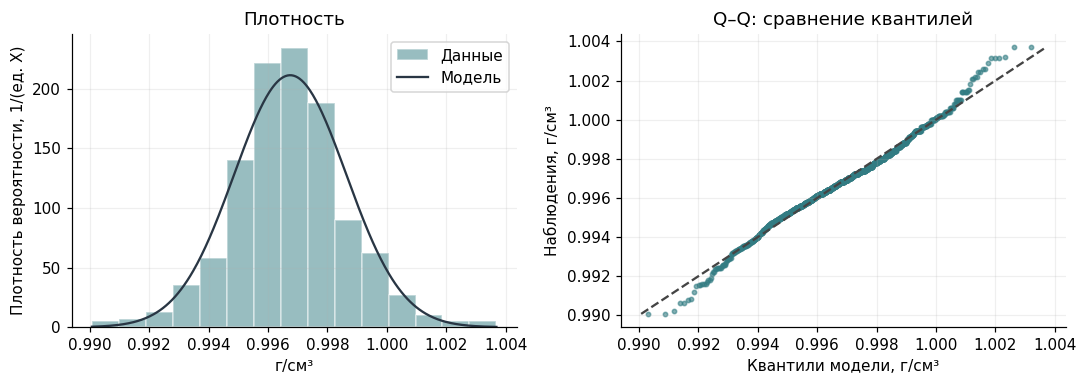

Остаточный сахар — Логнормальное — единицы: г/л


,Уровень,Данные,Модель,Модель − данные
0,0.05,1.59,1.30014,-0.289858
1,0.25,1.9,1.83899,-0.0610123
2,0.5,2.2,2.34019,0.140189
3,0.75,2.6,2.97799,0.377989
4,0.95,5.1,4.21222,-0.887779


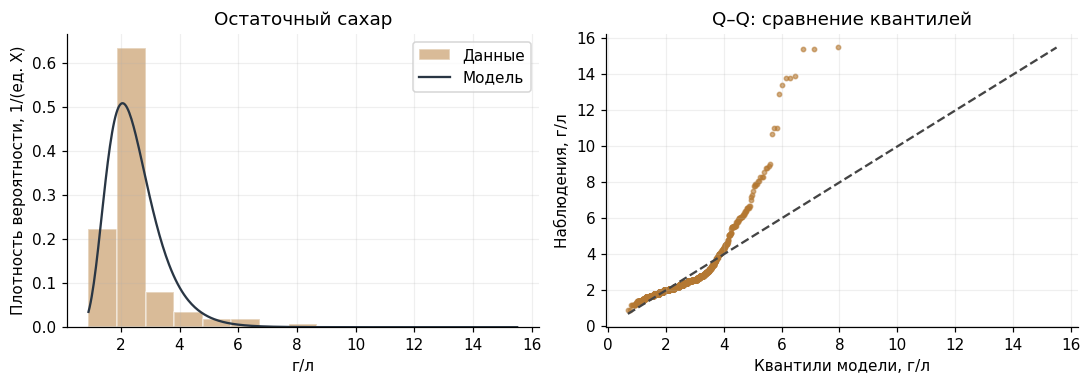

Параметры: для normal — μ, σ; для lognormal — μ_log, σ_log


,Величина,Модель,параметр 1,параметр 2
0,Спирт,Логнормальное,2.33902,0.0988685
1,Плотность,Нормальное,0.996747,0.00188674
2,Остаточный сахар,Логнормальное,0.850232,0.357332


In [38]:
models = {}
model_parameters = []
quantile_tables = {}
levels = np.array([0.05, 0.25, 0.5, 0.75, 0.95])

for column in columns:
    x = wine[column].to_numpy()
    if column == "density":
        mu, sigma = x.mean(), x.std(ddof=0)
        model = stats.norm(loc=mu, scale=sigma)
        model_name = "Нормальное"
        model_parameters.append({"Величина": names[column], "Модель": model_name, "параметр 1": mu, "параметр 2": sigma})
    else:
        logs = np.log(x)
        mu_log, sigma_log = logs.mean(), logs.std(ddof=0)
        model = stats.lognorm(s=sigma_log, scale=np.exp(mu_log), loc=0)
        model_name = "Логнормальное"
        model_parameters.append({"Величина": names[column], "Модель": model_name, "параметр 1": mu_log, "параметр 2": sigma_log})
    models[column] = model
    comparison = pd.DataFrame({
        "Уровень": levels,
        "Данные": np.quantile(x, levels),
        "Модель": model.ppf(levels),
    })
    comparison["Модель − данные"] = comparison["Модель"] - comparison["Данные"]
    quantile_tables[column] = comparison
    print(names[column], "—", model_name, "— единицы:", units[column])
    display(comparison)

    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
    grid = np.linspace(x.min(), x.max(), 400)
    axes[0].hist(x, bins=15, density=True, alpha=0.5, color=colors[column], edgecolor="white", label="Данные")
    axes[0].plot(grid, model.pdf(grid), color="#293644", label="Модель")
    axes[0].set(xlabel=units[column], ylabel="Плотность вероятности, 1/(ед. X)", title=names[column])
    axes[0].legend()
    probabilities = (np.arange(len(x)) + 0.5) / len(x)
    theoretical = model.ppf(probabilities)
    axes[1].scatter(theoretical, np.sort(x), s=8, color=colors[column], alpha=0.6)
    low = min(theoretical.min(), x.min())
    high = max(theoretical.max(), x.max())
    axes[1].plot([low, high], [low, high], "--", color="#444444")
    axes[1].set(xlabel="Квантили модели, " + units[column], ylabel="Наблюдения, " + units[column], title="Q–Q: сравнение квантилей")
    if column == "density":
        for ax in axes:
            ax.ticklabel_format(axis="x", style="plain", useOffset=False)
        axes[1].ticklabel_format(axis="y", style="plain", useOffset=False)
    plt.tight_layout()
    plt.show()

print("Параметры: для normal — μ, σ; для lognormal — μ_log, σ_log")
display(pd.DataFrame(model_parameters))


У плотности нормальная модель достаточно близко описывает центральные квантили,
хотя в хвостах остаются отклонения. У спирта логнормальная модель даёт 5-й процентиль
около 8.814 % об. вместо 9.2 % об.; совпадение неполное.
У сахара она даёт 95-й процентиль около 4.212 г/л вместо 5.1 г/л и завышает третий квартиль.
Следовательно, положительность и асимметрия сами по себе не обеспечивают хорошую подгонку.

**Для дальнейших расчётов вероятностей используются эмпирические частоты.**
Гладкие модели здесь нужны для сравнения форм и понимания их ограничений.


<a id="rounding"></a>



### Влияние округления на статистики

Округление до целого уничтожило бы почти всю информацию о плотности.
Для демонстрации используем 2 знака у спирта и сахара и 5 знаков у плотности.
Основные расчёты выше и ниже используют исходные числа.
Таблицы частот округлённых значений сохраняются отдельно.


In [39]:
digits = {"alcohol": 2, "density": 5, "residual sugar": 2}
rounded_frequencies = {}
rounding_rows = []
for column in columns:
    rounded = wine[column].round(digits[column])
    table = frequency_table(rounded)
    rounded_frequencies[column] = table
    rounding_rows.append({
        "Величина": names[column],
        "Знаков": digits[column],
        "Уникальных до": wine[column].nunique(),
        "Уникальных после": rounded.nunique(),
        "Среднее исходное": wine[column].mean(),
        "E после округления": (table["x"] * table["p_i"]).sum(),
        "Сумма p_i": table["p_i"].sum(),
    })
display(pd.DataFrame(rounding_rows))


,Величина,Знаков,Уникальных до,Уникальных после,Среднее исходное,E после округления,Сумма p_i
0,Спирт,2,65,65,10.423,10.423,1
1,Плотность,5,436,436,0.996747,0.996747,1
2,Остаточный сахар,2,91,91,2.53881,2.53881,1


<a id="normalization"></a>
## 2. Нормализация и стандартизация

У величин разные единицы и масштабы. Для сравнения отклонений от типичного уровня используем

$$z_i=\frac{x_i-\bar x}{s},$$

где $s$ посчитано с `ddof=1`. Тогда среднее преобразованных данных равно нулю,
а их стандартное отклонение с тем же `ddof=1` равно единице.
Для диапазона от 0 до 1 применим min–max:

$$u_i=\frac{x_i-x_{\min}}{x_{\max}-x_{\min}}.$$

Оба преобразования сохраняют порядок значений и форму распределения с точностью до
сдвига и изменения масштаба. **Стандартизация не превращает произвольные данные в нормальные.**
Если исходная величина действительно $N(\mu,\sigma^2)$ и известны её параметры,
то $(X-\mu)/\sigma\sim N(0,1)$. Для плотности это только приближённая интерпретация
с оценёнными параметрами. Min–max чувствителен к минимуму и максимуму.


,Среднее z,"s(z), ddof=1",min min–max,max min–max
alcohol,8.88734e-17,1,0,1
density,-3.46606e-14,1,0,1
residual sugar,-1.15535e-16,1,0,1


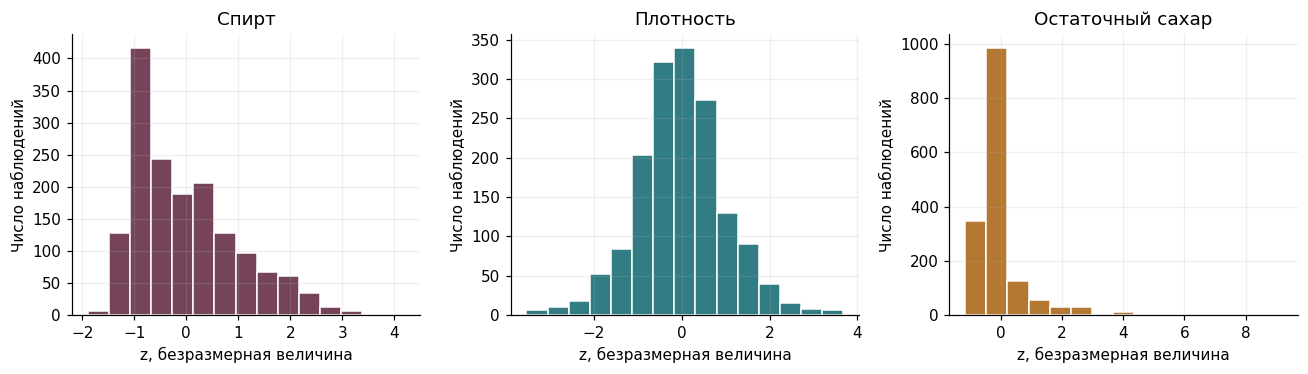

In [40]:
z_scores = (wine[columns] - wine[columns].mean()) / wine[columns].std(ddof=1)
minmax = (wine[columns] - wine[columns].min()) / (wine[columns].max() - wine[columns].min())
normalization_check = pd.DataFrame({
    "Среднее z": z_scores.mean(),
    "s(z), ddof=1": z_scores.std(ddof=1),
    "min min–max": minmax.min(),
    "max min–max": minmax.max(),
})
display(normalization_check)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, column in zip(axes, columns):
    ax.hist(z_scores[column], bins=15, color=colors[column], edgecolor="white")
    ax.set(title=names[column], xlabel="z, безразмерная величина", ylabel="Число наблюдений")
plt.tight_layout()
plt.show()


После стандартизации правый хвост сахара сохранился. Изменился масштаб, а не характер данных.
Остатки порядка 10⁻¹³ около нуля в таблице - погрешность вычислений.


<a id="dependence"></a>
## 3. Совместные вероятности, зависимость и гипотезы

### Сначала вероятности событий

Возьмём понятные численные пороги: спирт выше 11 % об., плотность выше 0.997 г/см³,
сахар выше 3 г/л. Это учебные пороги, не нормативы и не классификация вин.
Они фиксированы для расчётов ниже.

$$P_N(B)=\frac{n(B)}{N},\quad
P_N(B\cap C)=\frac{n(B\cap C)}{N},\quad
P_N(C\mid B)=\frac{n(B\cap C)}{n(B)}.$$

Независимость требует $P(B\cap C)=P(B)P(C)$ для любых событий соответствующих величин.
Для конечной таблицы неравенство хотя бы для одной пары событий уже показывает
эмпирическую зависимость. Чтобы судить о более широкой совокупности, учитывается случайная ошибка.


,Событие,Число,N,Вероятность
0,A > 11 % об.,408,1599,0.255159
1,D > 0.997 г/см³,678,1599,0.424015
2,S > 3 г/л,215,1599,0.134459


,B,C,n(B ∩ C),P(B ∩ C),P(B)P(C),P(C | B),P(C)
0,A > 11 % об.,D > 0.997 г/см³,66,0.0412758,0.108191,0.161765,0.424015
1,A > 11 % об.,S > 3 г/л,73,0.0456535,0.0343085,0.178922,0.134459
2,D > 0.997 г/см³,S > 3 г/л,152,0.0950594,0.0570126,0.224189,0.134459


,Пара,"Пирсон, все строки","Спирмен, все строки","Пирсон, без повторов"
0,Спирт — Плотность,-0.49618,-0.462445,-0.504995
1,Спирт — Остаточный сахар,0.0420754,0.116548,0.0632811
2,Плотность — Остаточный сахар,0.355283,0.422266,0.324522


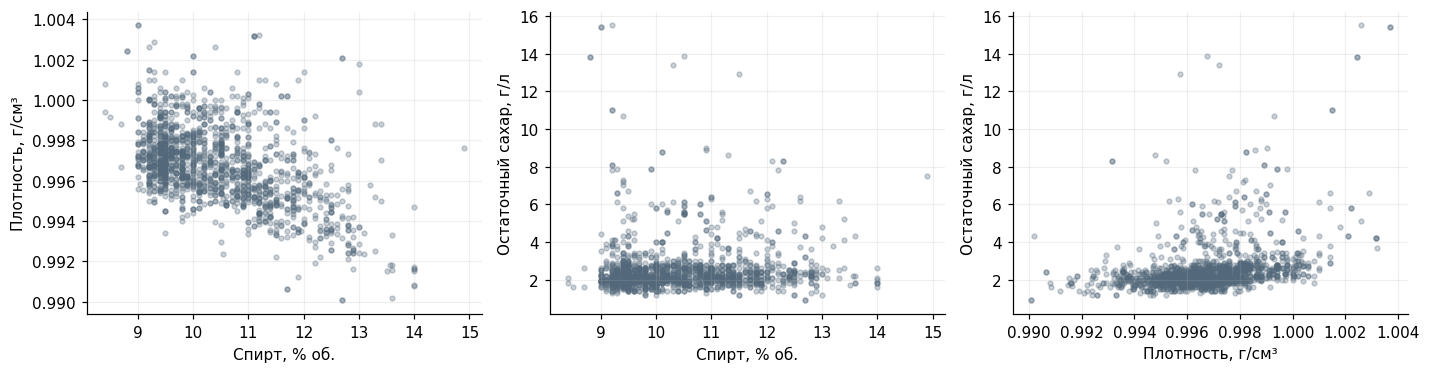

In [25]:
events = {
    "alcohol": wine["alcohol"] > 11,
    "density": wine["density"] > 0.997,
    "residual sugar": wine["residual sugar"] > 3,
}
event_labels = {"alcohol": "A > 11 % об.", "density": "D > 0.997 г/см³", "residual sugar": "S > 3 г/л"}
event_table = pd.DataFrame([
    {"Событие": event_labels[c], "Число": int(events[c].sum()), "N": N, "Вероятность": events[c].mean()}
    for c in columns
])
display(event_table)

joint_rows = []
for a, b in combinations(columns, 2):
    joint = events[a] & events[b]
    joint_rows.append({
        "B": event_labels[a], "C": event_labels[b],
        "n(B ∩ C)": joint.sum(),
        "P(B ∩ C)": joint.mean(),
        "P(B)P(C)": events[a].mean() * events[b].mean(),
        "P(C | B)": joint.sum() / events[a].sum(),
        "P(C)": events[b].mean(),
    })
joint_table = pd.DataFrame(joint_rows)
display(joint_table)

wine_unique = wine.drop_duplicates().copy()
correlation_rows = []
for a, b in combinations(columns, 2):
    correlation_rows.append({
        "Пара": names[a] + " — " + names[b],
        "Пирсон, все строки": wine[a].corr(wine[b]),
        "Спирмен, все строки": wine[a].corr(wine[b], method="spearman"),
        "Пирсон, без повторов": wine_unique[a].corr(wine_unique[b]),
    })
display(pd.DataFrame(correlation_rows))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, (a, b) in zip(axes, combinations(columns, 2)):
    ax.scatter(wine[a], wine[b], s=10, alpha=0.3, color="#53697b")
    ax.set(xlabel=names[a] + ", " + units[a], ylabel=names[b] + ", " + units[b])
    if a == "density":
        ax.ticklabel_format(axis="x", style="plain", useOffset=False)
    if b == "density":
        ax.ticklabel_format(axis="y", style="plain", useOffset=False)
plt.tight_layout()
plt.show()


Корреляция Пирсона описывает линейную связь, Спирмена — монотонную связь через ранги.
Для них здесь не вычисляются дополнительные p-значения.
У спирта и сахара Пирсон близок к нулю; одного этого недостаточно для вывода о независимости.

### Ровно три формальные гипотезы

1. $H_{01}$: содержание спирта и плотность независимы.
2. $H_{02}$: содержание спирта и остаточный сахар независимы.
3. $H_{03}$: плотность и остаточный сахар независимы.

Для каждой $H_1$ означает наличие зависимости. Проверка проводится на **1359 различных строках**.
Каждая величина разбивается на три примерно равные по численности группы с помощью `qcut`.
Из-за одинаковых измеренных значений размеры групп могут отличаться.
Число групп выбрано заранее; границы определяются по отдельным столбцам, а не по p-значениям.

Критерий Пирсона для таблицы сопряжённости [5]:

$$E_{ij}=\frac{n_{i\cdot}n_{\cdot j}}{n},\qquad
\chi^2=\sum_{ij}\frac{(O_{ij}-E_{ij})^2}{E_{ij}},\qquad
df=(r-1)(c-1)=4.$$

$O$ — наблюдаемые частоты, $E$ — ожидаемые при независимости.
Проверяем, что частоты достаточны для приближения критерием $\chi^2$.
Для семейства из трёх гипотез выбран уровень $\alpha=0.05$ и поправка Бонферрони:
сравниваем каждое $p$ с $0.05/3$, или $p_{adj}=\min(3p,1)$ с 0.05.
Вероятность хотя бы одной ложной значимости ограничивается суммой трёх уровней: $3\cdot0.05/3$.

Дополнительно оценивается сила связи через
$V=\sqrt{\chi^2/[n\min(r-1,c-1)]}$ (V Крамера).
Значимый результат для сгруппированных величин противоречит независимости исходных величин.
Незначимый результат не доказал бы независимость: группировка может скрывать часть связи.

Калибровка p-значений предполагает независимые наблюдения и подходящий отбор образцов.
В исходном источнике нет идентификаторов партий, поэтому эти условия нельзя полностью проверить.
Выводы тестов условны относительно этой модели; причинность они не устанавливают.


In [26]:
groups = {}
group_boundaries = []
for column in columns:
    groups[column], boundaries = pd.qcut(wine_unique[column], q=3, labels=False, retbins=True)
    group_boundaries.append({
        "Величина": names[column], "min": boundaries[0],
        "Граница 1": boundaries[1], "Граница 2": boundaries[2], "max": boundaries[3],
    })
display(pd.DataFrame(group_boundaries))
print("Группы 1, 2, 3: от меньших значений к большим; крайняя правая граница включается.")

hypothesis_rows = []
for number, (a, b) in enumerate(combinations(columns, 2), start=1):
    observed = pd.crosstab(groups[a] + 1, groups[b] + 1)
    chi2, p_value, dof, expected = stats.chi2_contingency(observed, correction=False)
    assert observed.to_numpy().min() >= 5 and expected.min() >= 5
    p_adjusted = min(3 * p_value, 1)
    v_cramer = np.sqrt(chi2 / (len(wine_unique) * min(observed.shape[0] - 1, observed.shape[1] - 1)))
    print(f"H0{number}: {names[a]} — {names[b]}; строки: {names[a]}, столбцы: {names[b]}")
    print("Наблюдаемые частоты:")
    display(observed)
    print("Ожидаемые частоты при независимости:")
    display(pd.DataFrame(expected, index=observed.index, columns=observed.columns))
    hypothesis_rows.append({
        "H0": f"H0{number}", "Пара": names[a] + " — " + names[b],
        "chi2": chi2, "df": dof, "p": p_value, "p_Bonferroni": p_adjusted,
        "V Крамера": v_cramer,
        "Решение": "отвергается" if p_adjusted < 0.05 else "не отвергается",
    })

hypothesis_results = pd.DataFrame(hypothesis_rows)
display(hypothesis_results)


,Величина,min,Граница 1,Граница 2,max
0,Спирт,8.4,9.7,10.8,14.9
1,Плотность,0.99007,0.996,0.9974,1.00369
2,Остаточный сахар,0.9,2,2.43333,15.5


Группы 1, 2, 3: от меньших значений к большим; крайняя правая граница включается.
H01: Спирт — Плотность; строки: Спирт, столбцы: Плотность
Наблюдаемые частоты:


density,1,2,3
alcohol,,,
1,59,200,214
2,114,165,165
3,288,95,59


Ожидаемые частоты при независимости:


density,1,2,3
alcohol,,,
1,160.451,160.103,152.446
2,150.614,150.287,143.099
3,149.935,149.61,142.455


H02: Спирт — Остаточный сахар; строки: Спирт, столбцы: Остаточный сахар
Наблюдаемые частоты:


... (4 outputs left out)

residual sugar,1,2,3
density,,,
1,240,148,73
2,210,129,121
3,77,102,259


Ожидаемые частоты при независимости:


residual sugar,1,2,3
density,,,
1,178.769,128.564,153.667
2,178.381,128.286,153.333
3,169.85,122.15,146


,H0,Пара,chi2,df,p,p_Bonferroni,V Крамера,Решение
0,H01,Спирт — Плотность,308.593,4,1.5169e-65,4.55069e-65,0.336952,отвергается
1,H02,Спирт — Остаточный сахар,17.5542,4,0.00150789,0.00452368,0.0803647,отвергается
2,H03,Плотность — Остаточный сахар,220.223,4,1.67849e-46,5.03548e-46,0.284647,отвергается


Все три нулевые гипотезы отвергаются после поправки Бонферрони.
Скорректированные p-значения: около $4.55\cdot10^{-65}$ для спирта и плотности,
0.00452 для спирта и сахара и $5.04\cdot10^{-46}$ для плотности и сахара.
Зависимость спирта и сахара намного слабее по V Крамера (около 0.080), чем связи с плотностью
(около 0.337 и 0.285). Малое p не означает большую силу эффекта.

На всех строках корреляция спирта и плотности отрицательная ($r\approx-0.496$),
а сахара и плотности положительная ($r\approx0.355$). Это согласуется с ожидаемым влиянием
состава на плотность, но наблюдательные данные не отделяют вклад каждого вещества от остальных.
Удаление полных повторов не меняет знаки этих связей. Для спирта и сахара слабая линейная
корреляция ($r\approx0.042$) сосуществует со значимой зависимостью распределения по группам.


<a id="sampling"></a>
## 4. Генеральная совокупность и две выборки

Из $N=1599$ строк берутся две простые случайные выборки объема $n=400$:
с возвращением и без. В первом случае один и тот же номер строки может выпасть несколько раз.
Во втором случае номера не повторяются, но измеренные значения всё равно могут совпасть.
Во всех столбцах выбираются **одни и те же строки**, чтобы сохранить связи между признаками.

Объём 400 выбран по ориентиру для среднего: при независимом отборе
$1.96\sigma/\sqrt n\leq0.1\sigma$ даёт $n\geq385$.
Это приближенная точность 95%-го интервала при применимости ЦПТ, а не гарантия
воспроизведения редких значений или всех статистик.

Точные дисперсии выборочного среднего для конечной таблицы [6]:

$$\operatorname{Var}(\bar X_{WR})=\frac{V_N}{n},\qquad
\operatorname{Var}(\bar X_{WOR})=\frac{V_N}{n}\frac{N-n}{N-1}.$$

Здесь WR — с возвращением, WOR — без возвращения.
У выборки без возвращения действует поправка на конечный объем; при $n=N$ ошибка исчезает.
Для сравнения дисперсии с одним и тем же $V_N$ используем оценки

$$\widehat V_{WR}=s^2,\qquad \widehat V_{WOR}=\frac{N-1}{N}s^2.$$

Во втором случае $s^2$ само по себе несмещенно оценивает $S_N^2=NV_N/(N-1)$.
Эта небольшая разница в знаменателях здесь учтена.


In [27]:
rng_sample = np.random.default_rng(SEED)
n_sample = 400
indices_wr = rng_sample.choice(N, size=n_sample, replace=True)
indices_wor = rng_sample.choice(N, size=n_sample, replace=False)
samples = {
    "С возвращением": wine.iloc[indices_wr][columns],
    "Без возвращения": wine.iloc[indices_wor][columns],
}
print("Объём каждой выборки:", n_sample)
print("Уникальных номеров строк с возвращением:", len(np.unique(indices_wr)))
print("Уникальных номеров строк без возвращения:", len(np.unique(indices_wor)))

sample_metrics = {}
for column in columns:
    comparison = pd.DataFrame({
        "Генеральная таблица": describe_values(wine[column]),
        "С возвращением": describe_values(samples["С возвращением"][column]),
        "Без возвращения": describe_values(samples["Без возвращения"][column]),
    })
    sample_metrics[column] = comparison
    print(names[column], "—", units[column])
    display(comparison)


Объём каждой выборки: 400
Уникальных номеров строк с возвращением: 361
Уникальных номеров строк без возвращения: 400
Спирт — % об.


,Генеральная таблица,С возвращением,Без возвращения
Количество,1599,400,400
Уникальных значений,65,47,51
Сумма,16666.3,4195.22,4182.02
Среднее,10.423,10.488,10.455
Медиана,10.2,10.2,10.1
Мода (все значения),9.5,9.5,9.5
Минимум,8.4,8.5,8.4
Максимум,14.9,14,14
Размах,6.5,5.5,5.6
"Дисперсия, ddof=0",1.13494,1.23857,1.209


Плотность — г/см³


,Генеральная таблица,С возвращением,Без возвращения
Количество,1599,400,400
Уникальных значений,436,194,223
Сумма,1593.8,398.681,398.641
Среднее,0.996747,0.996703,0.996603
Медиана,0.99675,0.99668,0.99662
Мода (все значения),0.9972,0.9976,0.9972
Минимум,0.99007,0.99007,0.99007
Максимум,1.00369,1.0032,1.00369
Размах,0.01362,0.01313,0.01362
"Дисперсия, ddof=0",3.5598e-06,3.91964e-06,3.4339e-06


Остаточный сахар — г/л


,Генеральная таблица,С возвращением,Без возвращения
Количество,1599,400,400
Уникальных значений,91,53,55
Сумма,4059.55,1008.3,990.7
Среднее,2.53881,2.52075,2.47675
Медиана,2.2,2.2,2.2
Мода (все значения),2,2,2.1
Минимум,0.9,0.9,0.9
Максимум,15.5,13.4,15.4
Размах,14.6,12.5,14.5
"Дисперсия, ddof=0",1.98665,1.49393,1.53652


Количество и сумма зависят от объёма и не должны совпадать у таблицы и выборки.
Минимум и максимум тоже обычно различаются: редкие крайние образцы могут не попасть в 400 строк.
Для оценки исходного распределения полезнее сравнивать среднее, медиану, разброс и квантили.
Ниже отдельно показаны ошибки оценок среднего и дисперсии, а также частоты выбранных событий.


,Величина,Отбор,Ошибка среднего,Ошибка среднего / σ_N,V_hat,"Ошибка V_hat, %",ДИ 95%: низ,ДИ 95%: верх,μ_N внутри
0,Спирт,С возвращением,0.0650586,0.0610687,1.24168,9.40505,10.3788,10.5972,True
1,Спирт,Без возвращения,0.0320586,0.0300925,1.21127,6.72594,10.3616,10.5485,True
2,Плотность,С возвращением,-4.36542e-05,-0.0231373,3.92947e-06,10.3844,0.996509,0.996897,True
3,Плотность,Без возвращения,-0.000143404,-0.0760062,3.44035e-06,-3.35554,0.996446,0.996761,True
4,Остаточный сахар,С возвращением,-0.0180555,-0.01281,1.49768,-24.6131,2.40082,2.64068,True
5,Остаточный сахар,Без возвращения,-0.0620555,-0.044027,1.53941,-22.5124,2.37143,2.58207,True


,Событие,Таблица,С возвращением,Без возвращения
0,A > 11 % об.,0.255159,0.305,0.28
1,D > 0.997 г/см³,0.424015,0.4325,0.4175
2,S > 3 г/л,0.134459,0.1375,0.1125


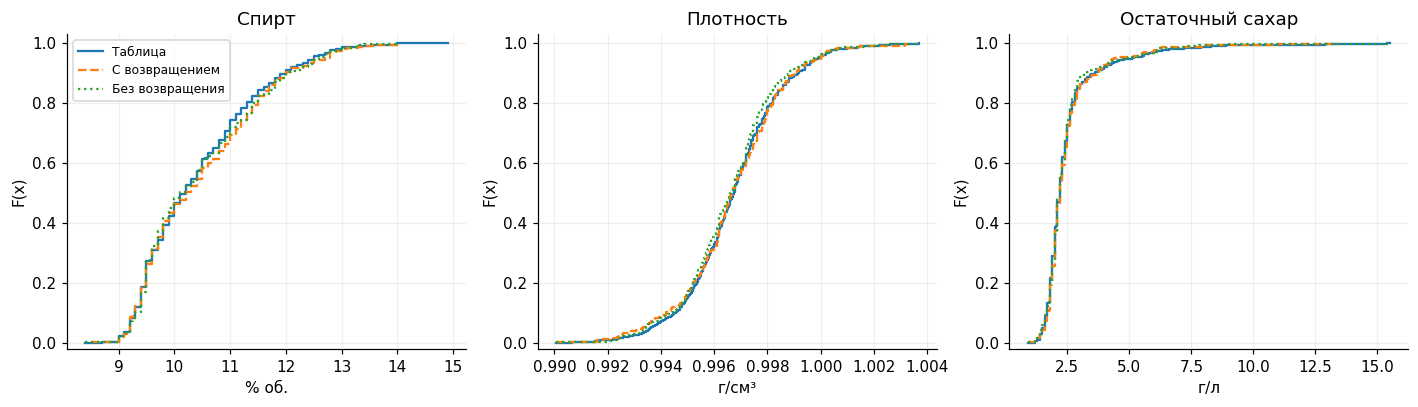

В этом запуске точное среднее попало в **6 из 6** приближённых интервалов. Максимальная абсолютная ошибка среднего равна **0.076 σ_N**. Это результат одного отбора: он не гарантирует такое же совпадение при другом seed. 95% относится к доле покрывающих интервалов при повторении процедуры, а не к вероятности для уже фиксированного неизвестного параметра. Интервалы маргинальные, не одновременные.

In [28]:
sample_errors = []
for column in columns:
    population_mean = wine[column].mean()
    population_var = wine[column].var(ddof=0)
    for design, sample in samples.items():
        s = sample[column]
        is_wor = design == "Без возвращения"
        estimated_var = s.var(ddof=1) * ((N - 1) / N if is_wor else 1)
        se = s.std(ddof=1) / np.sqrt(n_sample)
        if is_wor:
            se *= np.sqrt(1 - n_sample / N)
        lower, upper = s.mean() - 1.96 * se, s.mean() + 1.96 * se
        sample_errors.append({
            "Величина": names[column], "Отбор": design,
            "Ошибка среднего": s.mean() - population_mean,
            "Ошибка среднего / σ_N": (s.mean() - population_mean) / np.sqrt(population_var),
            "V_hat": estimated_var,
            "Ошибка V_hat, %": 100 * (estimated_var / population_var - 1),
            "ДИ 95%: низ": lower, "ДИ 95%: верх": upper,
            "μ_N внутри": lower <= population_mean <= upper,
        })
sample_error_table = pd.DataFrame(sample_errors)
display(sample_error_table)

probability_comparison = []
thresholds = {"alcohol": 11, "density": 0.997, "residual sugar": 3}
for column in columns:
    probability_comparison.append({
        "Событие": event_labels[column],
        "Таблица": events[column].mean(),
        "С возвращением": (samples["С возвращением"][column] > thresholds[column]).mean(),
        "Без возвращения": (samples["Без возвращения"][column] > thresholds[column]).mean(),
    })
display(pd.DataFrame(probability_comparison))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, column in zip(axes, columns):
    for label, data, style in [("Таблица", wine[column], "-"),
                               ("С возвращением", samples["С возвращением"][column], "--"),
                               ("Без возвращения", samples["Без возвращения"][column], ":")]:
        table = frequency_table(data)
        ax.step(table["x"], table["F_N(x)"], where="post", label=label, linestyle=style)
    ax.set(title=names[column], xlabel=units[column], ylabel="F(x)", ylim=(-0.02, 1.03))
    if column == "density":
        ax.ticklabel_format(axis="x", style="plain", useOffset=False)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

inside_count = int(sample_error_table["μ_N внутри"].sum())
max_mean_error = sample_error_table["Ошибка среднего / σ_N"].abs().max()
display(Markdown(
    f"В этом запуске точное среднее попало в **{inside_count} из 6** приближённых интервалов. "
    f"Максимальная абсолютная ошибка среднего равна **{max_mean_error:.3f} σ_N**. "
    "Это результат одного отбора: он не гарантирует такое же совпадение при другом seed. "
    "95% относится к доле покрывающих интервалов при повторении процедуры, а не к вероятности "
    "для уже фиксированного неизвестного параметра. Интервалы маргинальные, не одновременные."
))


У сахара обе выборки недооценили дисперсию: примерно на **24.6%** с возвращением
и **22.5%** без возвращения. При этом ошибки среднего невелики.
Поэтому совпадение средних ещё не означает точного воспроизведения разброса и хвостов.

<a id="consistency"></a>
## 5. Состоятельность оценок

Оценка состоятельна, если для любого $\varepsilon>0$

$$P(|\hat\theta_n-\theta|>\varepsilon)\longrightarrow0\quad\text{при }n\to\infty.$$

При независимом отборе с возвращением закон больших чисел даёт состоятельность среднего.
Например, неравенство Чебышёва даёт верхнюю границу
$P(|\bar X-\mu_N|>\varepsilon)\leq V_N/(n\varepsilon^2)$.
Для дисперсии используется сходимость первого и второго выборочных моментов;
в конечной эмпирической совокупности все моменты конечны [7].

Эмпирический опыт: для каждого объёма выполняются **1000 независимых повторных отборов**.
Изучаются оценка среднего и оценка $V_N$ с поправкой для отбора без возвращения.
Рассчитываются смещение (средняя ошибка), RMSE и доля ошибок больше выбранного допуска:

$$\operatorname{RMSE}=\sqrt{\frac{1}{B}\sum_{b=1}^{B}(\hat\theta_b-\theta)^2}.$$

Допуск для среднего равен $0.1\sqrt{V_N}$, для дисперсии — $0.1V_N$.
Доля превышений приближает вероятность из определения состоятельности при этих допусках.
При отборе без возвращения из фиксированных 1599 строк нельзя буквально устремить $n$ к бесконечности:
здесь проверяется уменьшение ошибки при приближении $n$ к $N$.
График сам по себе не является доказательством предельной теоремы.


Спирт


,Отбор,n,Смещение среднего,RMSE среднего,SE по формуле,Смещение V_hat,RMSE V_hat,P(|ошибка среднего| > 0.1σ),P(|ошибка V_hat| > 0.1V)
0,С возвращением,20,0.00562689,0.232803,0.238216,-0.00675891,0.358273,0.662,0.739
3,С возвращением,50,0.00809922,0.150189,0.150661,0.00447903,0.233189,0.468,0.65
6,С возвращением,100,0.000555386,0.107198,0.106533,0.0135495,0.166205,0.323,0.502
9,С возвращением,400,-0.000829739,0.0534827,0.0532667,0.00030253,0.082251,0.049,0.152
12,С возвращением,800,-0.00112051,0.0376823,0.0376653,-0.000807391,0.0619281,0.006,0.067
15,С возвращением,1500,0.000119663,0.0262526,0.0275068,0.000878161,0.0419899,0,0.004
18,С возвращением,1599,4.85408e-05,0.026816,0.0266417,-0.001152,0.0424188,0,0.01
21,Без возвращения,20,0.00608689,0.234825,0.236796,-0.00128602,0.377929,0.646,0.758
24,Без возвращения,50,-0.00297478,0.150832,0.148333,0.00813869,0.23776,0.483,0.615
27,Без возвращения,100,0.00633655,0.101357,0.103181,0.00942786,0.161187,0.265,0.482


Плотность


,Отбор,n,Смещение среднего,RMSE среднего,SE по формуле,Смещение V_hat,RMSE V_hat,P(|ошибка среднего| > 0.1σ),P(|ошибка V_hat| > 0.1V)
1,С возвращением,20,-2.18202e-05,0.000428427,0.000421889,-3.32367e-08,1.38056e-06,0.668,0.796
4,С возвращением,50,-1.16116e-05,0.000273781,0.000266826,5.82317e-09,8.37889e-07,0.498,0.681
7,С возвращением,100,-5.11387e-06,0.000188758,0.000188674,4.85067e-08,6.20755e-07,0.32,0.577
10,С возвращением,400,2.60635e-06,9.20147e-05,9.43372e-05,6.39018e-10,3.11413e-07,0.041,0.247
13,С возвращением,800,-3.18346e-06,6.7308e-05,6.67065e-05,-7.41574e-09,2.14167e-07,0.005,0.098
16,С возвращением,1500,9.68906e-07,4.85184e-05,4.87155e-05,4.14885e-09,1.55836e-07,0,0.032
19,С возвращением,1599,-1.16128e-06,4.86313e-05,4.71833e-05,3.05872e-10,1.462e-07,0,0.015
22,Без возвращения,20,-1.42812e-05,0.000416072,0.000419373,-2.77021e-08,1.39619e-06,0.658,0.794
25,Без возвращения,50,-2.39557e-06,0.000271918,0.000262703,8.13654e-09,8.27867e-07,0.488,0.685
28,Без возвращения,100,-5.32547e-06,0.000180722,0.000182737,6.0847e-09,5.79575e-07,0.294,0.531


Остаточный сахар


,Отбор,n,Смещение среднего,RMSE среднего,SE по формуле,Смещение V_hat,RMSE V_hat,P(|ошибка среднего| > 0.1σ),P(|ошибка V_hat| > 0.1V)
2,С возвращением,20,-0.0052905,0.315577,0.315171,-0.0553118,2.44259,0.644,0.944
5,С возвращением,50,0.0067705,0.207528,0.199332,0.0460875,1.54568,0.49,0.92
8,С возвращением,100,0.0010925,0.147759,0.140949,0.0282042,1.16158,0.333,0.88
11,С возвращением,400,-0.00247613,0.0712749,0.0704744,-0.0197315,0.548978,0.041,0.734
14,С возвращением,800,-0.00204925,0.0504568,0.0498329,-0.0086646,0.395979,0.006,0.619
17,С возвращением,1500,-0.000903137,0.0359898,0.0363928,-0.00136635,0.283124,0,0.468
20,С возвращением,1599,-0.00237048,0.0356306,0.0352482,-0.00670581,0.275696,0,0.49
23,Без возвращения,20,-0.005043,0.313195,0.313292,-0.0986128,2.36223,0.686,0.924
26,Без возвращения,50,0.0031275,0.200847,0.196252,0.0611067,1.5863,0.47,0.93
29,Без возвращения,100,-0.0043655,0.132559,0.136513,-0.0494401,1.03173,0.289,0.891


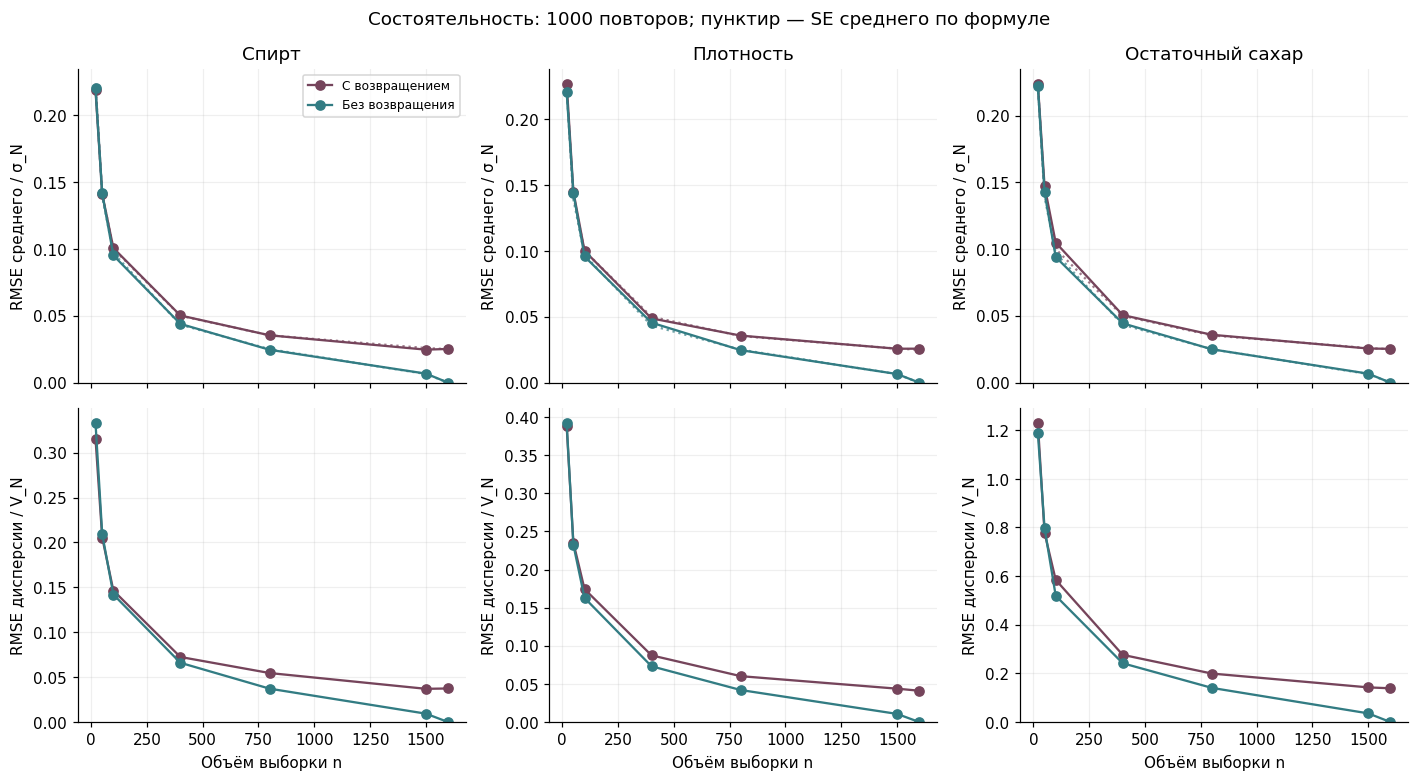

,Величина,Отбор,n,RMSE среднего,RMSE V_hat,P(|ошибка среднего| > 0.1σ),P(|ошибка V_hat| > 0.1V)
0,Спирт,С возвращением,20,0.232803,0.358273,0.662,0.739
1,Плотность,С возвращением,20,0.000428427,1.38056e-06,0.668,0.796
2,Остаточный сахар,С возвращением,20,0.315577,2.44259,0.644,0.944
9,Спирт,С возвращением,400,0.0534827,0.082251,0.049,0.152
10,Плотность,С возвращением,400,9.20147e-05,3.11413e-07,0.041,0.247
11,Остаточный сахар,С возвращением,400,0.0712749,0.548978,0.041,0.734
18,Спирт,С возвращением,1599,0.026816,0.0424188,0,0.01
19,Плотность,С возвращением,1599,4.86313e-05,1.462e-07,0,0.015
20,Остаточный сахар,С возвращением,1599,0.0356306,0.275696,0,0.49
21,Спирт,Без возвращения,20,0.234825,0.377929,0.646,0.758


In [29]:
rng_consistency = np.random.default_rng(SEED + 1)
values = wine[columns].to_numpy()
population_mean = values.mean(axis=0)
population_var = values.var(axis=0, ddof=0)
population_sd = np.sqrt(population_var)
sample_sizes = [20, 50, 100, 400, 800, 1500, N]
B = 1000
consistency_rows = []

for replacement, design in [(True, "С возвращением"), (False, "Без возвращения")]:
    for n in sample_sizes:
        mean_estimates = np.empty((B, len(columns)))
        variance_estimates = np.empty_like(mean_estimates)
        for b in range(B):
            chosen = rng_consistency.choice(N, size=n, replace=replacement)
            sample = values[chosen]
            mean_estimates[b] = sample.mean(axis=0)
            variance_estimates[b] = sample.var(axis=0, ddof=1)
        if not replacement:
            variance_estimates *= (N - 1) / N

        for j, column in enumerate(columns):
            mean_error = mean_estimates[:, j] - population_mean[j]
            variance_error = variance_estimates[:, j] - population_var[j]
            theoretical_se = population_sd[j] / np.sqrt(n)
            if not replacement:
                theoretical_se *= np.sqrt((N - n) / (N - 1))
            consistency_rows.append({
                "Величина": names[column], "Отбор": design, "n": n,
                "Смещение среднего": mean_error.mean(),
                "RMSE среднего": np.sqrt(np.mean(mean_error ** 2)),
                "SE по формуле": theoretical_se,
                "Смещение V_hat": variance_error.mean(),
                "RMSE V_hat": np.sqrt(np.mean(variance_error ** 2)),
                "P(|ошибка среднего| > 0.1σ)": np.mean(np.abs(mean_error) > 0.1 * population_sd[j]),
                "P(|ошибка V_hat| > 0.1V)": np.mean(np.abs(variance_error) > 0.1 * population_var[j]),
            })

consistency = pd.DataFrame(consistency_rows)
for column in columns:
    print(names[column])
    display(consistency[consistency["Величина"] == names[column]].drop(columns="Величина"))

fig, axes = plt.subplots(2, 3, figsize=(13, 7.2), sharex=True)
for j, column in enumerate(columns):
    for design, color in [("С возвращением", "#75445b"), ("Без возвращения", "#327c83")]:
        part = consistency[(consistency["Величина"] == names[column]) & (consistency["Отбор"] == design)]
        axes[0, j].plot(part["n"], part["RMSE среднего"] / population_sd[j], "o-", color=color, label=design)
        axes[0, j].plot(part["n"], part["SE по формуле"] / population_sd[j], ":", color=color, alpha=0.7)
        axes[1, j].plot(part["n"], part["RMSE V_hat"] / population_var[j], "o-", color=color, label=design)
    axes[0, j].set(title=names[column], ylabel="RMSE среднего / σ_N", ylim=(0, None))
    axes[1, j].set(xlabel="Объём выборки n", ylabel="RMSE дисперсии / V_N", ylim=(0, None))
axes[0, 0].legend(fontsize=8)
fig.suptitle("Состоятельность: 1000 повторов; пунктир — SE среднего по формуле")
plt.tight_layout()
plt.show()

brief_consistency = consistency[consistency["n"].isin([20, 400, N])]
display(brief_consistency[["Величина", "Отбор", "n", "RMSE среднего", "RMSE V_hat",
                           "P(|ошибка среднего| > 0.1σ)", "P(|ошибка V_hat| > 0.1V)"]])


In [30]:
lines = []
for column in columns:
    part = consistency[(consistency["Величина"] == names[column]) & (consistency["Отбор"] == "С возвращением")].set_index("n")
    first, last = part.loc[20], part.loc[N]
    lines.append(
        f"- **{names[column]}:** RMSE среднего снизилась с {first['RMSE среднего']:.6g} "
        f"до {last['RMSE среднего']:.6g} {units[column]}; "
        f"доля ошибок среднего больше 0.1σ — с {first['P(|ошибка среднего| > 0.1σ)']:.3f} "
        f"до {last['P(|ошибка среднего| > 0.1σ)']:.3f}."
    )
display(Markdown("Результат отбора с возвращением:\n\n" + "\n".join(lines)))


Результат отбора с возвращением:

- **Спирт:** RMSE среднего снизилась с 0.232803 до 0.026816 % об.; доля ошибок среднего больше 0.1σ — с 0.662 до 0.000.
- **Плотность:** RMSE среднего снизилась с 0.000428427 до 4.86313e-05 г/см³; доля ошибок среднего больше 0.1σ — с 0.668 до 0.000.
- **Остаточный сахар:** RMSE среднего снизилась с 0.315577 до 0.0356306 г/л; доля ошибок среднего больше 0.1σ — с 0.644 до 0.000.

С ростом объёма в целом уменьшаются RMSE и доли больших ошибок. Оценка дисперсии сахара сходится
заметно медленнее из-за редких больших значений. Даже при $n=1599$ с возвращением
ошибка его дисперсии превышает 10% в **49% повторов**. Сахар особенно наглядно показывает,
почему один удачный маленький набор ещё не подтверждает точность оценки.

При отборе без возвращения и $n=N$ используются все строки, поэтому оценки совпадают
с генеральными значениями с точностью вычислений. При отборе с возвращением и том же $n$
часть строк повторяется, часть не попадает в выборку, и ошибка остаётся.
Уменьшение ошибки наблюдается в серии повторений; отдельная траектория не обязана быть монотонной.
Нулевая доля ошибок в 1000 повторах означает отсутствие таких случаев в опыте,
а не доказанную нулевую вероятность события.


<a id="outliers"></a>
## 6. Влияние искусственных выбросов
К отдельной копии каждой одномерной серии добавляются два крайних значения:
одно маленькое и одно большое. Их интервалы заданы в коде, `seed` фиксирован.
Это **искусственные ошибочные записи**, а не настоящие наблюдения и не модель обычного вина.
Они не попадают в предыдущие оценки, гипотезы и выборки.

Сравним все основные метрики, заново пересчитаем $p_i$, $F_N$ и $E_N(X)$.
На ящиках с усами показывается весь диапазон, включая добавленные точки.
Это позволяет видеть сами выбросы, а не скрывать их ограничением оси.


Спирт — добавлены: [0.622566, 53.871696] % об.


,Исходные данные,С искусственными выбросами
Количество,1599,1601
Уникальных значений,65,67
Сумма,16666.3,16720.8
Среднее,10.423,10.444
Медиана,10.2,10.2
Мода (все значения),9.5,9.5
Минимум,8.4,0.622566
Максимум,14.9,53.8717
Размах,6.5,53.2491
"Дисперсия, ddof=0",1.13494,2.3722


Сумма вероятностей: 1; E_N(X): 10.4440002
Плотность — добавлены: [0.740577, 1.396918] г/см³


,Исходные данные,С искусственными выбросами
Количество,1599,1601
Уникальных значений,436,438
Сумма,1593.8,1595.94
Среднее,0.996747,0.996837
Медиана,0.99675,0.99675
Мода (все значения),0.9972,0.9972
Минимум,0.99007,0.740577
Максимум,1.00369,1.39692
Размах,0.01362,0.656341
"Дисперсия, ddof=0",3.5598e-06,0.000144559


Сумма вероятностей: 1; E_N(X): 0.996836624
Остаточный сахар — добавлены: [0.074348, 125.71881] г/л


,Исходные данные,С искусственными выбросами
Количество,1599,1601
Уникальных значений,91,93
Сумма,4059.55,4185.34
Среднее,2.53881,2.61421
Медиана,2.2,2.2
Мода (все значения),2,2
Минимум,0.9,0.0743476
Максимум,15.5,125.719
Размах,14.6,125.644
"Дисперсия, ddof=0",1.98665,11.4597


Сумма вероятностей: 1; E_N(X): 2.6142056


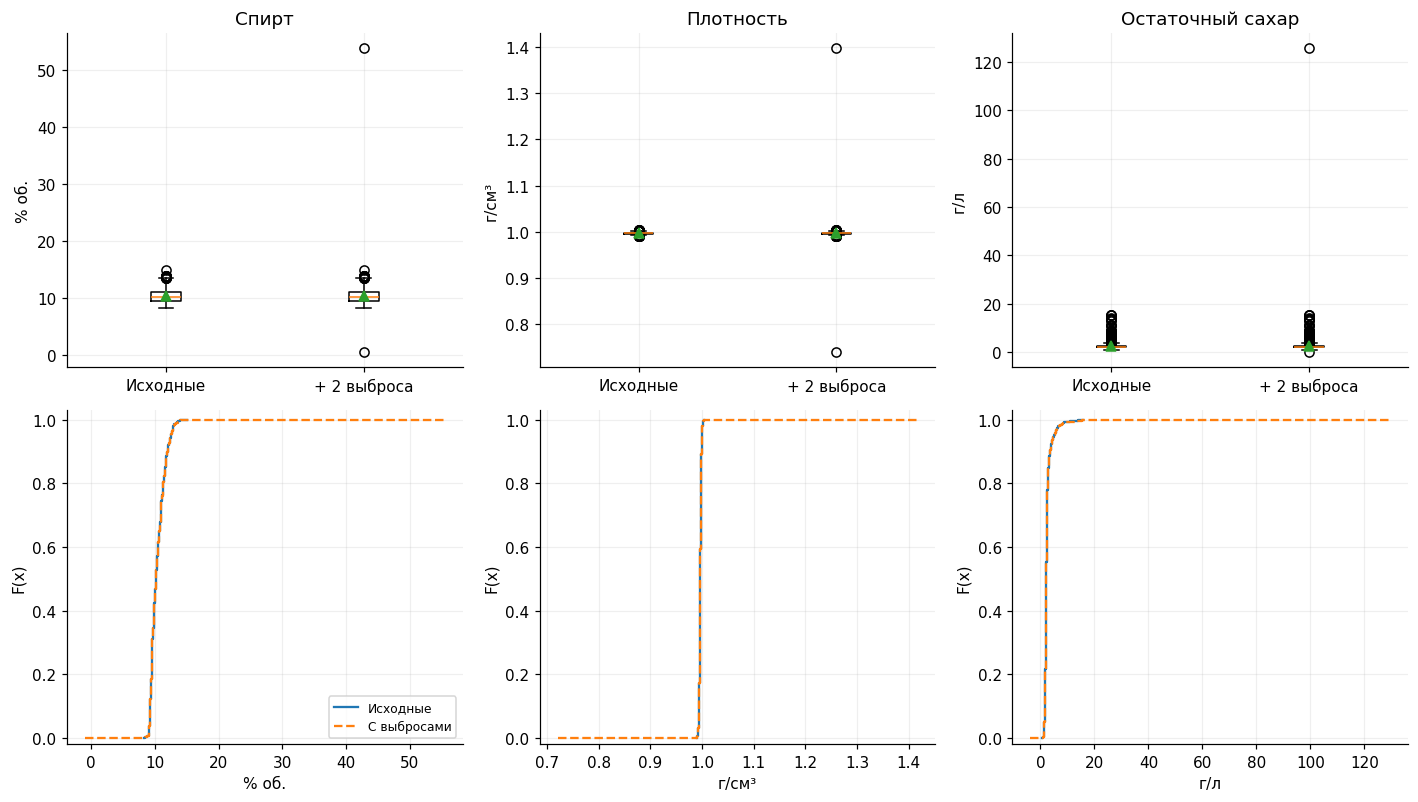

,Величина,Изменение среднего,Изменение медианы,"Изменение s, раз",Изменение IQR
0,Спирт,0.021017,0,1.44574,0
1,Плотность,8.99451e-05,0,6.3725,5e-06
2,Остаточный сахар,0.0754001,0,2.40173,0


In [31]:
rng_outliers = np.random.default_rng(SEED + 2)
outlier_ranges = {
    "alcohol": ((0.5, 1.5), (50, 65)),
    "density": ((0.70, 0.80), (1.30, 1.40)),
    "residual sugar": ((0.05, 0.2), (100, 130)),
}
with_outliers = {}
outlier_frequencies = {}
outlier_effect_rows = []

for column in columns:
    low_range, high_range = outlier_ranges[column]
    added = [rng_outliers.uniform(*low_range), rng_outliers.uniform(*high_range)]
    artificial = pd.Series(added, name=column)
    enlarged = pd.concat([wine[column].reset_index(drop=True), artificial], ignore_index=True)
    with_outliers[column] = enlarged
    table = frequency_table(enlarged)
    outlier_frequencies[column] = table
    print(names[column], "— добавлены:", [round(x, 6) for x in added], units[column])
    display(pd.DataFrame({"Исходные данные": describe_values(wine[column]), "С искусственными выбросами": describe_values(enlarged)}))
    expectation = (table["x"] * table["p_i"]).sum()
    print(f"Сумма вероятностей: {table['p_i'].sum():.17g}; E_N(X): {expectation:.9g}")
    assert np.isclose(table["p_i"].sum(), 1)
    assert np.isclose(expectation, enlarged.mean())
    outlier_effect_rows.append({
        "Величина": names[column],
        "Изменение среднего": enlarged.mean() - wine[column].mean(),
        "Изменение медианы": enlarged.median() - wine[column].median(),
        "Изменение s, раз": enlarged.std(ddof=1) / wine[column].std(ddof=1),
        "Изменение IQR": (enlarged.quantile(.75) - enlarged.quantile(.25)) - (wine[column].quantile(.75) - wine[column].quantile(.25)),
    })

fig, axes = plt.subplots(2, 3, figsize=(13, 7.4))
for j, column in enumerate(columns):
    axes[0, j].boxplot([wine[column], with_outliers[column]], showmeans=True)
    axes[0, j].set_xticks([1, 2], ["Исходные", "+ 2 выброса"])
    axes[0, j].set(title=names[column], ylabel=units[column])
    for label, data, style in [("Исходные", wine[column], "-"), ("С выбросами", with_outliers[column], "--")]:
        table = frequency_table(data)
        pad = (data.max() - data.min()) * .03
        xx = np.r_[data.min() - pad, table["x"], data.max() + pad]
        yy = np.r_[0, table["F_N(x)"], 1]
        axes[1, j].step(xx, yy, where="post", label=label, linestyle=style)
    axes[1, j].set(xlabel=units[column], ylabel="F(x)", ylim=(-0.02, 1.03))
axes[1, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()
outlier_effects = pd.DataFrame(outlier_effect_rows)
display(outlier_effects)


Медиана в этом опыте практически не меняется, а стандартное отклонение заметно возрастает.
Для среднего важна не только доля добавленных точек, но и их удалённость от центра.
Это иллюстрирует устойчивость медианы к небольшому числу крайних записей; она не означает,
что медиана вообще никогда не меняется при добавлении данных.

Кривые распределения почти накладываются: добавлены только две точки к 1599,
поэтому максимальное изменение CDF не превышает $2/1601\approx0.00125$.
При этом моментам достаточно малого количества очень далёких точек, чтобы заметно измениться.
Среднее и дисперсия не «неправильные» метрики — они отвечают на другие вопросы
и чувствительны к хвостам. Удалять реальные большие значения только ради красивого графика нельзя.


<a id="resume"></a>
## Lab resume

### Итоговые метрики


In [32]:
summary = pd.DataFrame({
    "Единица": pd.Series(units),
    "N": wine[columns].count(),
    "Среднее": wine[columns].mean(),
    "Медиана": wine[columns].median(),
    "s, ddof=1": wine[columns].std(ddof=1),
    "Q1": wine[columns].quantile(.25),
    "Q3": wine[columns].quantile(.75),
    "Асимметрия": wine[columns].skew(),
}).loc[columns]
display(summary.rename(index=names))
display(hypothesis_results[["H0", "Пара", "p_Bonferroni", "V Крамера", "Решение"]])


,Единица,N,Среднее,Медиана,"s, ddof=1",Q1,Q3,Асимметрия
Спирт,% об.,1599,10.423,10.2,1.06567,9.5,11.1,0.860829
Плотность,г/см³,1599,0.996747,0.99675,0.00188733,0.9956,0.997835,0.0712877
Остаточный сахар,г/л,1599,2.53881,2.2,1.40993,1.9,2.6,4.54066


,H0,Пара,p_Bonferroni,V Крамера,Решение
0,H01,Спирт — Плотность,4.55069e-65,0.336952,отвергается
1,H02,Спирт — Остаточный сахар,0.00452368,0.0803647,отвергается
2,H03,Плотность — Остаточный сахар,5.03548e-46,0.284647,отвергается


### Выводы первого спринта

1. У трёх величин разная форма распределения. Плотность близка к симметричной,
   у спирта есть правый хвост, у остаточного сахара он выражен особенно сильно.
   Медиана сахара 2.2 г/л заметно ниже среднего 2.539 г/л.
2. Нормальная кривая достаточно близка к центральной части распределения плотности.
   Логнормальные модели спирта и сахара не воспроизводят все квантили.
   Поэтому вероятности рассчитаны по частотам исходной таблицы.
3. Все три гипотезы независимости отвергнуты при общем уровне 0.05 после поправки
   Бонферрони на копии без полных повторов. Наиболее слабая связь — между спиртом и сахаром.
   Плотность убывает с ростом спирта и возрастает с ростом сахара в наблюдаемых данных.
   Статистическая связь не равна доказанному химическому механизму.
4. В выборках по 400 строк максимальная ошибка среднего составила около $0.076\sigma_N$,
   а дисперсия сахара оказалась занижена примерно на 23–25%. Выборки также не обязаны
   содержать экстремумы исходной таблицы. В повторных опытах ошибки оценок среднего
   и дисперсии уменьшаются. Поправка на конечную совокупность важна при отборе без возвращения.
5. Нормализация меняет масштаб, но не устраняет асимметрию. Два искусственных выброса
   сильнее меняют среднее и разброс, чем медиану и центральные квантили.

Ограничения: изучается один набор красных вин; история исходного отбора и принадлежность
к партиям неизвестны. Частоты событий точно относятся к выбранной конечной таблице.
Выводы о новых винах и p-значения требуют дополнительных предположений об отборе.


### Литература

1. Cortez P., Cerdeira A., Almeida F., Matos T., Reis J. **Wine Quality** (2009).
   UCI Machine Learning Repository. [DOI: 10.24432/C56S3T](https://doi.org/10.24432/C56S3T).
   
2. Cortez P. et al. **Modeling wine preferences by data mining from physicochemical properties**.
   Decision Support Systems, 47(4), 547–553, 2009.
   [DOI: 10.1016/j.dss.2009.05.016](https://doi.org/10.1016/j.dss.2009.05.016).
  
3. NIST/SEMATECH. **Normal Distribution**.
   [Формулы и свойства](https://www.itl.nist.gov/div898/handbook/eda/section3/eda3661.htm).
4. NIST/SEMATECH. **Lognormal Distribution**.
   [Формулы, параметры и оценки](https://www.itl.nist.gov/div898/handbook/eda/section3/eda3669.htm).
5. SciPy. **chi2_contingency**.
   [Документация критерия и требования к частотам](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.contingency.chi2_contingency.html).
6. Penn State, STAT 506. **Estimating Population Mean and Total under SRS**.
   [Выборочный отбор и поправка на конечную совокупность](https://online.stat.psu.edu/stat506/Lesson01).
7. UC Berkeley, STAT 135. **Consistency**.
   [Закон больших чисел и состоятельность моментов](https://stat135.berkeley.edu/fall-2026/Modules/14-Consistency.html).
